Classes: [0 1 2 3 4 5]

X shape: (1200, 784)

Num of classes: 6

Accuracy: 0.7027777777777777


Confusion matrix:
 [[53  0  1  3  0  3]
 [ 3 39  5  8  2  3]
 [ 5 10 37  5  1  2]
 [ 4  5  8 37  2  4]
 [ 0  3  1  2 45  9]
 [ 1  4  3  3  7 42]]


Classification Report:

               precision    recall  f1-score   support

           0       0.80      0.88      0.84        60
           1       0.64      0.65      0.64        60
           2       0.67      0.62      0.64        60
           3       0.64      0.62      0.63        60
           4       0.79      0.75      0.77        60
           5       0.67      0.70      0.68        60

    accuracy                           0.70       360
   macro avg       0.70      0.70      0.70       360
weighted avg       0.70      0.70      0.70       360


Probabilities (first 6 samples):
[[2.73074453e-04 2.34721388e-09 1.99264183e-06 4.87163408e-05
  1.19798109e-04 9.99556416e-01]
 [1.13357236e-02 1.13882097e-01 8.38533058e-01 6.78873435e-

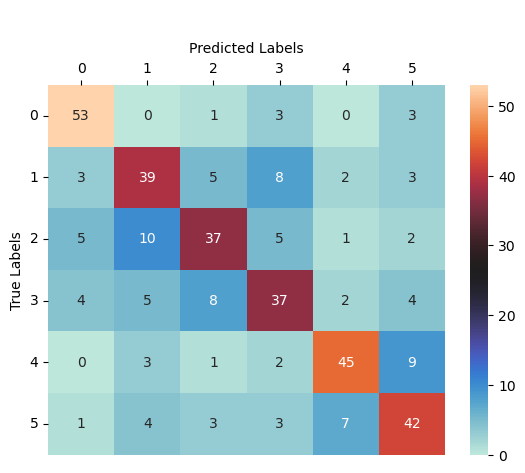



Number of misclassified test examples: 107


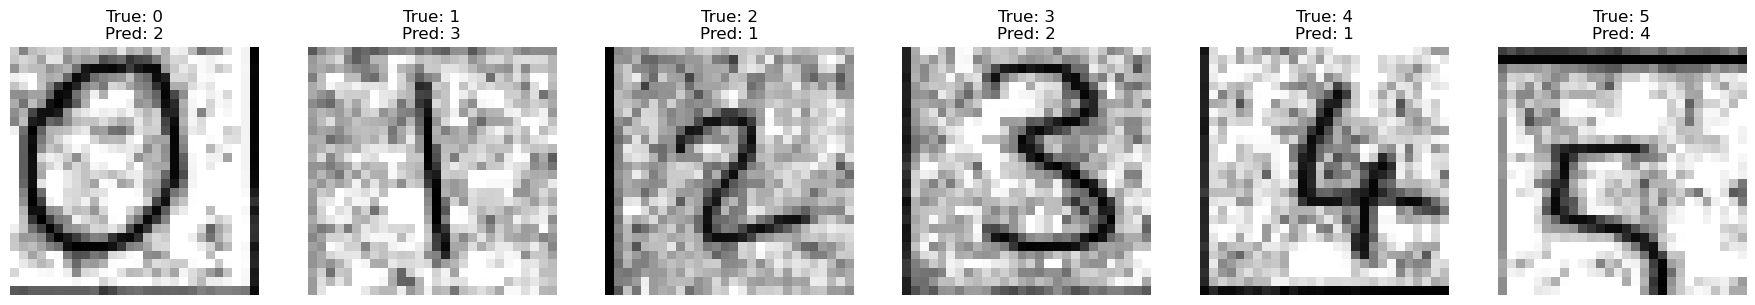

True: 0
Predicted: 2
Probabilities: ['0.0000', '0.0000', '1.0000', '0.0000', '0.0000', '0.0000']


True: 1
Predicted: 3
Probabilities: ['0.0032', '0.0826', '0.0007', '0.8415', '0.0212', '0.0508']


True: 2
Predicted: 1
Probabilities: ['0.0000', '0.7873', '0.0163', '0.0046', '0.1885', '0.0033']


True: 3
Predicted: 2
Probabilities: ['0.0026', '0.0004', '0.8736', '0.1234', '0.0000', '0.0000']


True: 4
Predicted: 1
Probabilities: ['0.0000', '0.7527', '0.0000', '0.2042', '0.0420', '0.0011']


True: 5
Predicted: 4
Probabilities: ['0.2412', '0.0000', '0.0001', '0.0000', '0.5390', '0.2198']




Number of classified test examples: 253


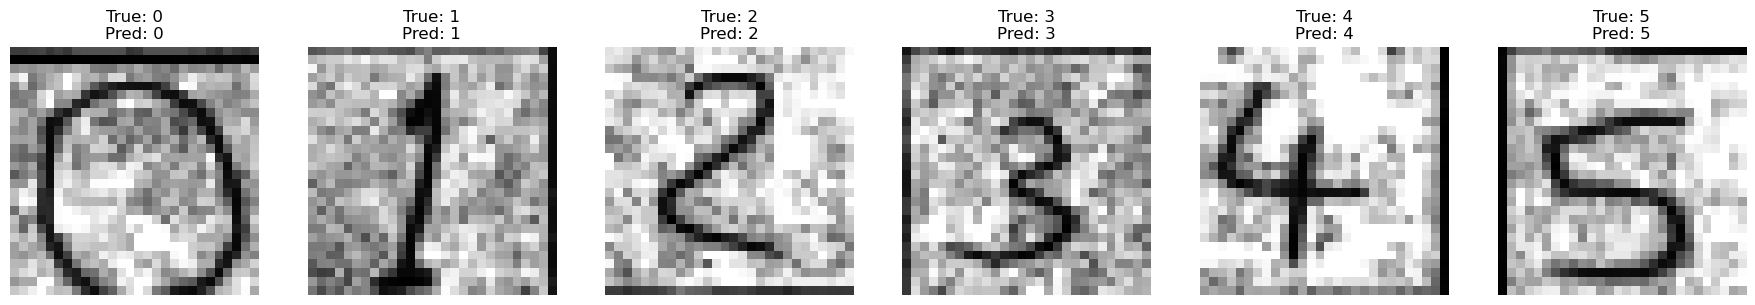

True: 0
Predicted: 0
Probabilities: ['0.9954', '0.0046', '0.0000', '0.0000', '0.0000', '0.0000']


True: 1
Predicted: 1
Probabilities: ['0.0000', '0.9675', '0.0029', '0.0290', '0.0001', '0.0004']


True: 2
Predicted: 2
Probabilities: ['0.0113', '0.1139', '0.8385', '0.0007', '0.0271', '0.0085']


True: 3
Predicted: 3
Probabilities: ['0.0000', '0.1055', '0.0003', '0.8925', '0.0007', '0.0009']


True: 4
Predicted: 4
Probabilities: ['0.0000', '0.2994', '0.0001', '0.0000', '0.6959', '0.0045']


True: 5
Predicted: 5
Probabilities: ['0.0003', '0.0000', '0.0000', '0.0000', '0.0001', '0.9996']




In [1]:
# ----------------------------
# Import required libraries
# ----------------------------

import numpy as np

# Load Iris dataset
from sklearn.datasets import load_iris

# Split data into training and testing subsets
from sklearn.model_selection import train_test_split

# Standardize features 
from sklearn.preprocessing import StandardScaler

# Logistic Regression model
from sklearn.linear_model import LogisticRegression

# Pipeline allows chaining multiple steps together
from sklearn.pipeline import Pipeline

# Evaluation metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report



# -------------------
# Set random seed
# -------------------

# Set random seed to 0 for reproducibility
# Ensures the same train/test split each time the notebook runs

SEED = 0
np.random.seed(SEED)



# -----------------------------
# Loading dataset of numbers
# -----------------------------

# Number dataset:
# Contains 6 classes from 0-5 with 200 of each number

import pandas as pd
from PIL import Image
from PIL import ImageFilter

data = pd.read_csv('dataset/labels.csv')
X = []
y= []
for filepath in data.filepath:
    image = Image.open(filepath) 
    image = np.array(image) 
    image = image.flatten()
    image = (image - min(image)) / (max(image) - min(image)) 
    X.append(image)

for label in data.label:
    y.append(label)



print("Classes:", np.unique(data.label))
print("\nX shape:", np.shape(X))
print("\nNum of classes:", len(np.unique(y)))



# --------------------
# Train-test split
# --------------------

# Split dataset:
# - 70% training data
# - 30% testing data
# stratify=y ensures class proportions remain balanced

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=SEED,
    stratify=y
)



# -------------------------------------------
# Multiclass Logistic Regression (Softmax)
# -------------------------------------------

# In multiclass logistic regression:
#
# For each class k, the model learns parameters:
#     s_k = w_k^T x + b_k     (a score for class k)
#
# These scores are transformed into probabilities using SOFTMAX:
#
#     P(y=k | x) = exp(s_k) / sum_j exp(s_j)
#
# This guarantees:
# - All probabilities are positive
# - Probabilities sum to 1
#
# The predicted class is:
#     argmax_k P(y=k | x)

clf = Pipeline([
    
    # Step 1: Standardize features
    # Logistic regression converges faster and more reliably
    # when features have mean 0 and variance 1
    ("scaler", StandardScaler()),

    # Step 2: Logistic Regression
    # solver="lbfgs" supports true multinomial (softmax) optimization
    # max_iter increased to ensure convergence
    ("softmax", LogisticRegression(
        max_iter=2000,
        random_state=SEED,
        solver="lbfgs"
    ))
])

# Training procedure:
# 1) Fit scaler on training data
# 2) Transform training data
# 3) Optimize softmax cross-entropy loss to learn weights

clf.fit(X_train, y_train)


# -----------------
# Evaluate model
# -----------------

# Predict class labels on unseen test data
y_pred = clf.predict(X_test)

# Accuracy = proportion of correctly classified samples
print("\nAccuracy:", accuracy_score(y_test, y_pred))

# Confusion matrix:
# Rows = true labels
# Columns = predicted labels
print("\n\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))

# Classification report provides:
# - Precision
# - Recall
# - F1-score
# - Support (number of true samples per class)
print("\n\nClassification Report:\n\n", classification_report(y_test, y_pred))


# --------------------------------
# Inspect Softmax probabilities
# --------------------------------

# predict_proba returns:
# shape = (n_samples, n_classes)
#
# Each row contains probabilities:
#   [P(class=0), P(class=1), P(class=2)]
#
# Each row sums to 1 due to softmax normalization.

proba = clf.predict_proba(X_test)

print("\nProbabilities (first 6 samples):")
print(proba)

# Predicted class = index of highest probability (argmax)
print("\nPredicted classes:", clf.predict(X_test))

import seaborn as sns
import matplotlib.pyplot as plt

matrix = confusion_matrix(y_test, y_pred)
heatmap=sns.heatmap(matrix,annot = matrix,cmap='icefire')
plt.title('\n\nPredicted Labels', fontsize=10)
plt.ylabel('True Labels')
plt.tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)
plt.yticks(rotation=0)
plt.show()



# -------------------------------------
# Show some misclassified examples
# -------------------------------------

misclassified_idx = np.where(y_test != y_pred)[0]

print(f"\n\nNumber of misclassified test examples: {len(misclassified_idx)}")

num_idx = []

# Loop through each class (0–5)
for digit in range(6):
    for idx in misclassified_idx:
        if y_test[idx] == digit:
            num_idx.append(idx)
            break  

num_show = len(num_idx)

if num_show > 0:
    fig, axes = plt.subplots(1, num_show, figsize=(3 * num_show, 3))

    if num_show == 1:
        axes = [axes]

    for i, idx in enumerate(num_idx):
        img = X_test[idx].reshape(28, 28)
        axes[i].imshow(img, cmap="gray", vmin=0, vmax=1)
        axes[i].set_title(f"True: {y_test[idx]}\nPred: {y_pred[idx]}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

for idx in num_idx:
    print("True:", y_test[idx])
    print("Predicted:", y_pred[idx])

    prob = proba[idx]
    probDp = [f"{p:.4f}" for p in prob]
    
    print("Probabilities:", probDp)
    print("\n")


# -----------------------------------
# Show some classified examples
# -----------------------------------

classified_idx = np.where(y_test == y_pred)[0]

print(f"\n\nNumber of classified test examples: {len(classified_idx)}")

num_idx = []

# Loop through each class (0–5)
for digit in range(6):
    for idx in classified_idx:
        if y_test[idx] == digit:
            num_idx.append(idx)
            break  

num_show = len(num_idx)

if num_show > 0:
    fig, axes = plt.subplots(1, num_show, figsize=(3 * num_show, 3))

    if num_show == 1:
        axes = [axes]

    for i, idx in enumerate(num_idx):
        img = X_test[idx].reshape(28, 28)
        axes[i].imshow(img, cmap="gray", vmin=0, vmax=1)
        axes[i].set_title(f"True: {y_test[idx]}\nPred: {y_pred[idx]}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

for idx in num_idx:
    print("True:", y_test[idx])
    print("Predicted:", y_pred[idx])

    prob = proba[idx]
    probDp = [f"{p:.4f}" for p in prob]
    
    print("Probabilities:", probDp)
    print("\n")